# Practical 10: Principal Component Analysis

## Aim
Statistics, boxplots, scatter plot, covariance matrix, scaling and PCA on the Wine data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["class"] = df["target"] + 1
df = df.drop(columns="target")
df.to_csv("wine.csv", index=False)

In [3]:
print("Shape:", df.shape)
print("Classes:", sorted(df["class"].unique()))
print(df.describe().round(3).T)

Shape: (178, 14)
Classes: [np.int64(1), np.int64(2), np.int64(3)]
                              count     mean  ...      75%      max
alcohol                       178.0   13.001  ...   13.678    14.83
malic_acid                    178.0    2.336  ...    3.082     5.80
ash                           178.0    2.367  ...    2.558     3.23
alcalinity_of_ash             178.0   19.495  ...   21.500    30.00
magnesium                     178.0   99.742  ...  107.000   162.00
total_phenols                 178.0    2.295  ...    2.800     3.88
flavanoids                    178.0    2.029  ...    2.875     5.08
nonflavanoid_phenols          178.0    0.362  ...    0.438     0.66
proanthocyanins               178.0    1.591  ...    1.950     3.58
color_intensity               178.0    5.058  ...    6.200    13.00
hue                           178.0    0.957  ...    1.120     1.71
od280/od315_of_diluted_wines  178.0    2.612  ...    3.170     4.00
proline                       178.0  746.893  ... 

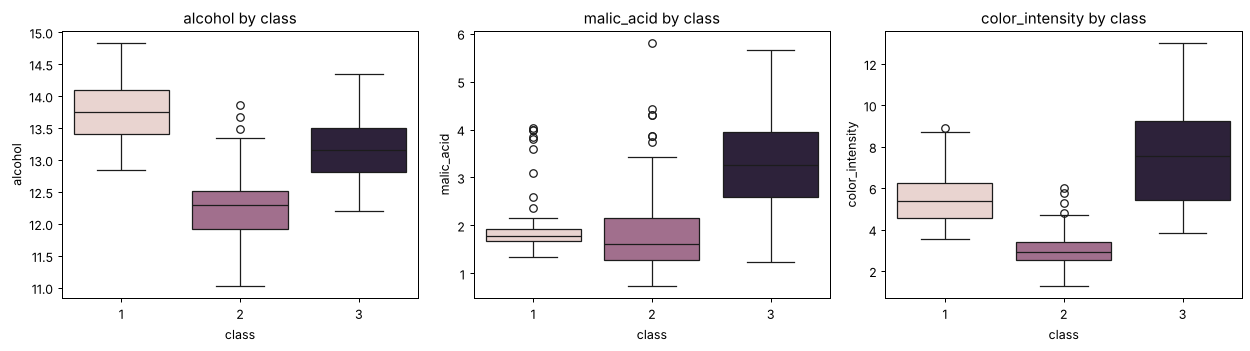

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["alcohol", "malic_acid", "color_intensity"]):
    sns.boxplot(data=df, x="class", y=col, hue="class", legend=False, ax=ax)
    ax.set_title(col + " by class")
plt.tight_layout()
plt.show()

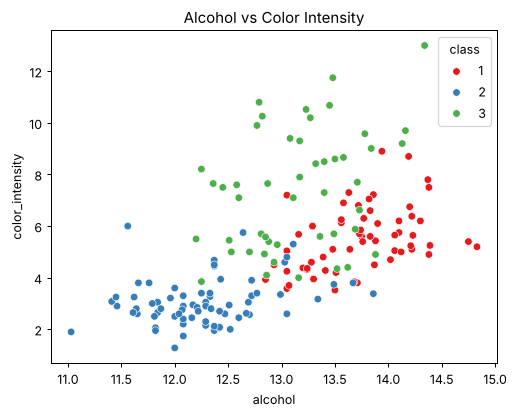

In [5]:
sns.scatterplot(data=df, x="alcohol", y="color_intensity", hue="class", palette="Set1")
plt.title("Alcohol vs Color Intensity")
plt.show()


Covariance matrix (first 5 columns):
                   alcohol  malic_acid    ash  alcalinity_of_ash  magnesium
alcohol              0.659       0.086  0.047             -0.841      3.140
malic_acid           0.086       1.248  0.050              1.076     -0.871
ash                  0.047       0.050  0.075              0.406      1.123
alcalinity_of_ash   -0.841       1.076  0.406             11.153     -3.975
magnesium            3.140      -0.871  1.123             -3.975    203.989


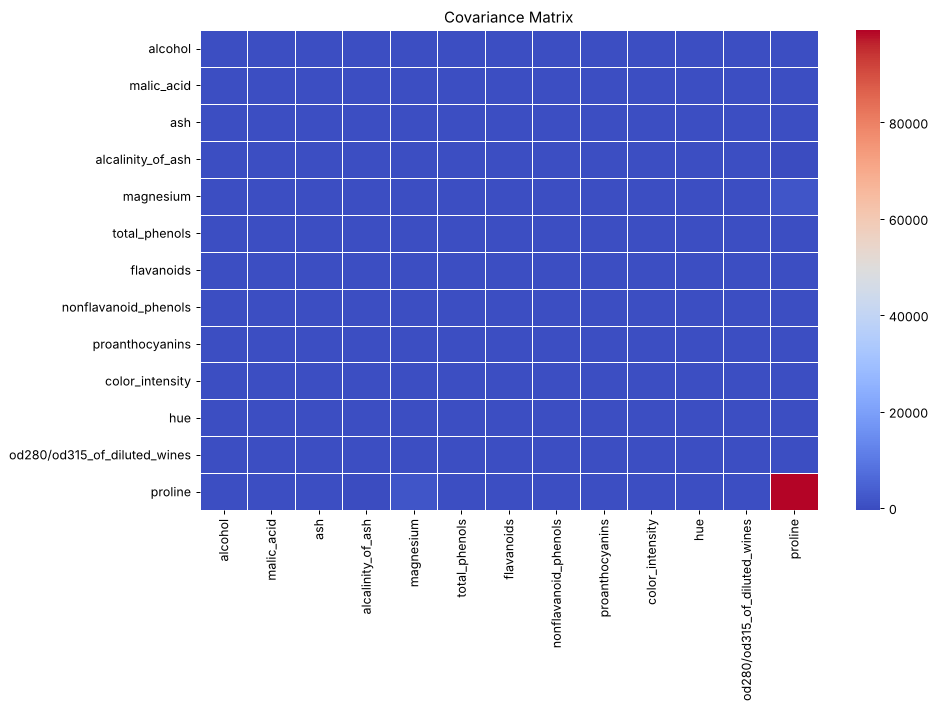

In [6]:
X = df.drop(columns="class")
cov = X.cov()
print("\nCovariance matrix (first 5 columns):")
print(cov.iloc[:5, :5].round(3))
plt.figure(figsize=(11, 8))
sns.heatmap(cov, cmap="coolwarm", linewidths=0.4)
plt.title("Covariance Matrix")
plt.tight_layout()
plt.show()

In [7]:
scaled = StandardScaler().fit_transform(X)
scaled_df = pd.DataFrame(scaled, columns=X.columns)
print("\nScaled mean:", scaled_df.mean().round(2).unique())
print("Scaled std:", scaled_df.std(ddof=0).round(2).unique())


Scaled mean: [-0.]
Scaled std: [1.]


In [8]:
pca = PCA(n_components=2)
pc = pd.DataFrame(pca.fit_transform(scaled), columns=["PC1", "PC2"])
pc["class"] = df["class"].values
print("\nFirst rows of PCA output:")
print(pc.head().round(4))
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total variance explained: %.2f%%" % (pca.explained_variance_ratio_.sum() * 100))


First rows of PCA output:
      PC1     PC2  class
0  3.3168  1.4435      1
1  2.2095 -0.3334      1
2  2.5167  1.0312      1
3  3.7571  2.7564      1
4  1.0089  0.8698      1
Explained variance ratio: [0.362  0.1921]
Total variance explained: 55.41%


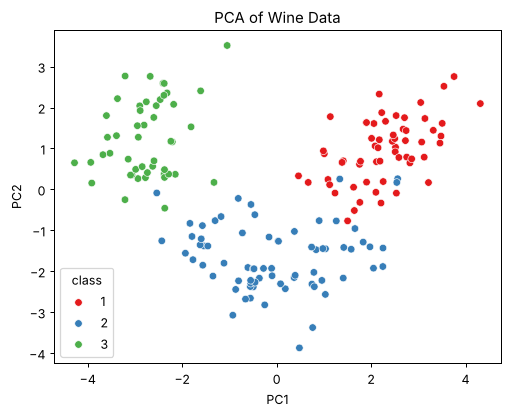

In [9]:
sns.scatterplot(data=pc, x="PC1", y="PC2", hue="class", palette="Set1")
plt.title("PCA of Wine Data")
plt.show()

In [10]:
print("\nResult: two components keep 55.41% of the variance and separate the three wine classes well.")


Result: two components keep 55.41% of the variance and separate the three wine classes well.
